# Network analysis of the three scraping methods

We collected the **same 380 Premier League matches** with three methods:
- **API** (TheSportsDB JSON API, one request per round), plus a **multithreaded** version of it
- **BeautifulSoup** (requests + HTML parsing of one season page)
- **Selenium** (a real headless Chrome browser)

In this notebook we compare how they use the network:
1. Performance metrics recorded by our scrapers (`data/metrics.csv`)
2. Packet captures made with `tcpdump` (`network/*.pcap`), analyzed with **scapy**
3. Connections seen with `ss` during the runs
4. Firewall test with `ufw`
5. Screenshots of the live tools (nload, iftop, Wireshark...)

## 1. Performance metrics from our scrapers

In [1]:
import re
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
NET = Path("../network")
FIG_DIR = Path("../report/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)
METHODS = ["api", "api_threaded", "bs4", "selenium"]
COLORS = {"api": "#4C72B0", "api_threaded": "#8172B3", "bs4": "#55A868", "selenium": "#C44E52"}

Every scraper run adds one row to `data/metrics.csv`, so some methods were run several times.
Below are **all runs**, and then we keep the **latest run of each method** for the comparison
(the latest runs are the ones we captured with tcpdump).

In [2]:
all_runs = pd.read_csv("../data/metrics.csv")
all_runs

,method,total_time_s,num_requests,bandwidth_kb,avg_latency_ms,rows_collected
0,api,516.40,41,668.3,130.7,380
1,bs4,0.57,1,1040.3,240.5,380
2,selenium,39.62,60,1686.4,2004.0,380
3,bs4,1.35,1,1040.3,966.6,380
4,api,516.57,41,668.3,134.8,380
5,bs4,0.53,1,1040.3,237.9,380
6,selenium,37.66,60,1686.4,293.0,380
7,api_threaded,413.53,50,730.8,109.4,380


In [3]:
latest = all_runs.groupby("method").tail(1).set_index("method").reindex(METHODS).dropna(how="all")
latest

,total_time_s,num_requests,bandwidth_kb,avg_latency_ms,rows_collected
method,,,,,
api,516.57,41,668.3,134.8,380
api_threaded,413.53,50,730.8,109.4,380
bs4,0.53,1,1040.3,237.9,380
selenium,37.66,60,1686.4,293.0,380


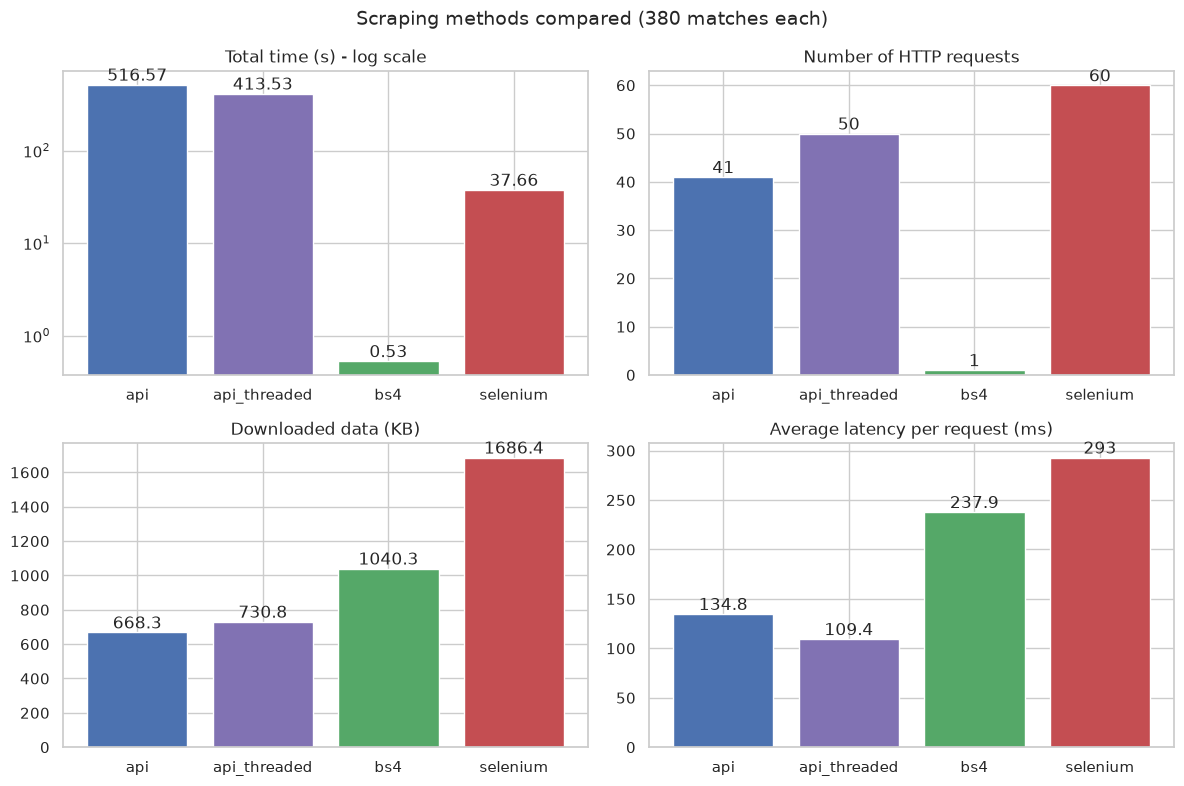

In [4]:
charts = [("total_time_s", "Total time (s) - log scale", True),
          ("num_requests", "Number of HTTP requests", False),
          ("bandwidth_kb", "Downloaded data (KB)", False),
          ("avg_latency_ms", "Average latency per request (ms)", False)]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (col, title, log) in zip(axes.flat, charts):
    bars = ax.bar(latest.index, latest[col], color=[COLORS[m] for m in latest.index])
    ax.bar_label(bars, fmt="%g")
    ax.set_title(title)
    if log:
        ax.set_yscale("log")
fig.suptitle("Scraping methods compared (380 matches each)", fontsize=14)
plt.tight_layout(); plt.savefig(FIG_DIR / "net_metrics_comparison.png", dpi=150); plt.show()

**What we see:**
- **Time:** BeautifulSoup is by far the fastest (under 1 second) because the website shows the whole
  season in **one HTML page**. Selenium needs ~40 s (starting a browser, loading all page resources,
  and reading 380 rows through the WebDriver). The API is the slowest in total, but not because the
  API is slow: the free key forces **38 requests (one per round)** and a strict **rate limit**,
  so most of the API time is spent **waiting**.
- **Requests:** 1 for BeautifulSoup, ~40 for the API (38 + retries after "429 Too Many Requests"),
  60 for Selenium (the browser also downloads CSS, JavaScript, images, ads and trackers).
- **Data:** the API downloads the least (only JSON data), Selenium the most.
- **Latency:** one API request is answered faster than one HTML page; latency of Selenium varies a
  lot between runs because many files are downloaded at the same time and wait in a queue.

In [5]:
# How much of the API time was waiting (rate limiting) and how much was real network time?
for m in ["api", "api_threaded"]:
    if m in latest.index:
        r = latest.loc[m]
        network_s = r.num_requests * r.avg_latency_ms / 1000
        print(f"{m:13}: total {r.total_time_s:6.1f} s, time inside requests ~{network_s:4.1f} s "
              f"-> {100 * (1 - network_s / r.total_time_s):.0f}% of the time is waiting")

api          : total  516.6 s, time inside requests ~ 5.5 s -> 99% of the time is waiting
api_threaded : total  413.5 s, time inside requests ~ 5.5 s -> 99% of the time is waiting


The multithreaded API scraper uses **4 threads** sharing one rate limiter (at most 1 request every
2 seconds = the documented 30 requests/minute). It was faster than the normal API scraper, but needed
more requests because it received many more "429 Too Many Requests" errors (see the conclusion).

## 2. Packet captures (tcpdump + scapy)

During each run, `network/run_measurements.sh` captured all web traffic (TCP ports 80 and 443) with
`tcpdump` into a `.pcap` file. We read these files with **scapy** and count:
- the number of packets and total bytes on the network (including all headers),
- the number of different servers (IP addresses) contacted and TCP connections opened,
- the **domain names** contacted: even with HTTPS, the first message of every connection
  (the TLS *ClientHello*) contains the server name in clear text (the **SNI** field).

(The `.pcap` files are not on GitHub because they are large; the summary is saved to
`network/pcap_summary.csv` so it can be read without them.)

In [6]:
from scapy.all import rdpcap, IP, TCP


def client_hello_server_name(data):
    """Read the server name (SNI) from the start of a TLS ClientHello message, or None."""
    try:
        if data[0] != 0x16 or data[5] != 0x01:      # 0x16 = TLS handshake, 0x01 = ClientHello
            return None
        pos = 5 + 4 + 2 + 32                         # record header, handshake header, version, random
        pos += 1 + data[pos]                         # session id
        pos += 2 + int.from_bytes(data[pos:pos + 2], "big")   # cipher suites
        pos += 1 + data[pos]                         # compression methods
        end = pos + 2 + int.from_bytes(data[pos:pos + 2], "big")
        pos += 2
        while pos + 4 <= end:                        # go through the extensions
            ext_type = int.from_bytes(data[pos:pos + 2], "big")
            ext_len = int.from_bytes(data[pos + 2:pos + 4], "big")
            if ext_type == 0:                        # extension 0 = server_name
                name_len = int.from_bytes(data[pos + 7:pos + 9], "big")
                return data[pos + 9:pos + 9 + name_len].decode()
            pos += 4 + ext_len
    except (IndexError, UnicodeDecodeError):
        return None
    return None


def analyze_pcap(path):
    packets = rdpcap(str(path))
    # Our own IP = the sender of the first SYN packet (we always open the connections)
    my_ip = next(p[IP].src for p in packets if IP in p and TCP in p and p[TCP].flags == "S")

    first_bytes = defaultdict(bytes)                 # first bytes sent on each connection
    server_bytes = Counter()
    for p in packets:
        if IP not in p or TCP not in p:
            continue
        server = p[IP].dst if p[IP].src == my_ip else p[IP].src
        server_bytes[server] += len(p)
        if p[IP].src == my_ip and len(p[TCP].payload) > 0:
            conn = (p[TCP].sport, p[IP].dst, p[TCP].dport)
            if len(first_bytes[conn]) < 4000:        # the ClientHello can be split over 2 packets
                first_bytes[conn] += bytes(p[TCP].payload)

    names = Counter()
    ip_to_names = defaultdict(set)                   # server IP -> domain names (from the SNI)
    for (sport, server_ip, dport), data in first_bytes.items():
        name = client_hello_server_name(data)
        if name:
            names[name] += 1
            ip_to_names[server_ip].add(name)

    # Bytes per domain. One IP can serve several domains (e.g. Cloudflare), then we show all names.
    # IPs without a known name are kept as IP addresses.
    domain_bytes = Counter()
    for ip, n in server_bytes.items():
        domain_bytes[" + ".join(sorted(ip_to_names[ip])) or ip] += n

    syns = sum(1 for p in packets if TCP in p and p[TCP].flags == "S")   # new connections opened
    times = np.array([float(p.time) for p in packets])
    return {
        "packets": len(packets),
        "total_kb": round(sum(len(p) for p in packets) / 1024, 1),
        "servers_ip": len(server_bytes),
        "tcp_connections": syns,
        "domains": len(names),
        "duration_s": round(times.max() - times.min(), 1),
        "domain_names": " ".join(sorted(names)),
        "_times": times - times.min(),
        "_names": names,
        "_domain_bytes": domain_bytes,
    }

In [7]:
pcap_results = {}
for m in METHODS:
    path = NET / f"{m}.pcap"
    if path.exists():
        pcap_results[m] = analyze_pcap(path)
    else:
        print(f"(no capture for {m})")

if pcap_results:
    summary = pd.DataFrame({m: {k: v for k, v in r.items() if not k.startswith("_")}
                            for m, r in pcap_results.items()}).T
    summary.to_csv(NET / "pcap_summary.csv")
else:                                                # no .pcap files (e.g. cloned from GitHub)
    summary = pd.read_csv(NET / "pcap_summary.csv", index_col=0)
summary.drop(columns="domain_names")

(no capture for api_threaded)


,packets,total_kb,servers_ip,tcp_connections,domains,duration_s
api,381,184.0,1,1,1,516.6
bs4,38,35.7,1,1,1,0.5
selenium,4297,7934.6,12,24,12,37.5


The multithreaded scraper was not captured with tcpdump (it was written after the measurement run),
so it only appears in the metrics of part 1.

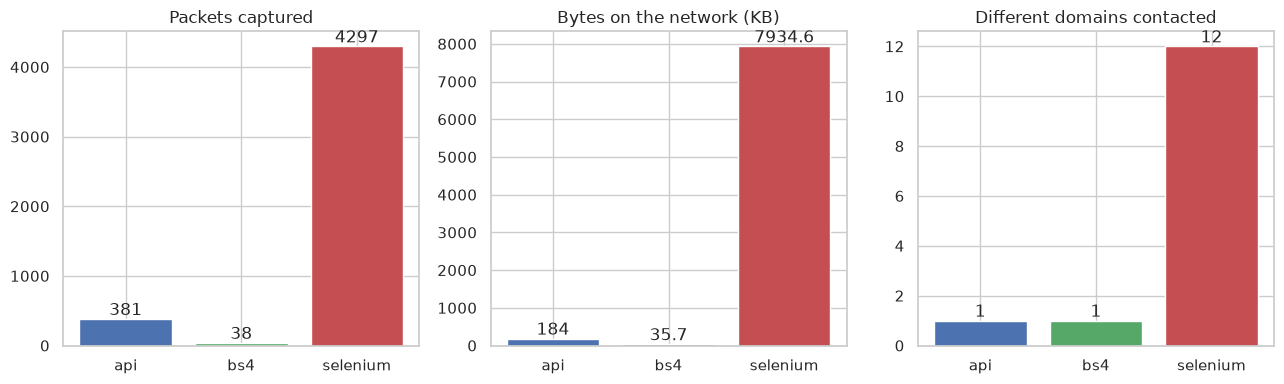

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, col, title in zip(axes, ["packets", "total_kb", "domains"],
                          ["Packets captured", "Bytes on the network (KB)", "Different domains contacted"]):
    bars = ax.bar(summary.index, summary[col].astype(float), color=[COLORS[m] for m in summary.index])
    ax.bar_label(bars, fmt="%g"); ax.set_title(title)
plt.tight_layout(); plt.savefig(FIG_DIR / "net_pcap_summary.png", dpi=150); plt.show()

### Domains contacted by each method (from the TLS SNI)

In [9]:
for m, r in pcap_results.items():
    print(f"{m}: {r['tcp_connections']} TCP connections, {r['domains']} domains")
    for name, n in r["_names"].most_common():
        print(f"    {n:3} x {name}")

api: 1 TCP connections, 1 domains
      1 x www.thesportsdb.com
bs4: 1 TCP connections, 1 domains
      1 x www.thesportsdb.com
selenium: 24 TCP connections, 12 domains
      6 x r2.thesportsdb.com
      3 x optimizationguide-pa.googleapis.com
      2 x accounts.google.com
      2 x update.googleapis.com
      2 x www.thesportsdb.com
      1 x plausible.io
      1 x googlechromelabs.github.io
      1 x www.google.com
      1 x www.googletagmanager.com
      1 x static.cloudflareinsights.com
      1 x content-autofill.googleapis.com
      1 x www.google.com.lb


The API and BeautifulSoup only talk to **www.thesportsdb.com** (through one reused connection,
thanks to `requests.Session`). Selenium's browser opens many connections to many domains: the image
server, Google (fonts, ads, analytics, tag manager), Cloudflare insights, and also Chrome's own
background services. All of this is traffic we do not need for the data.

### Where did Selenium's traffic go?

We add up the bytes per server (like *Wireshark > Statistics > Conversations*) and put each domain
in a group: the website itself, **Selenium Manager** (Selenium's tool that checks which ChromeDriver
version to use, it downloads version lists from GitHub at every start), **Chrome's own background
services** (updates, Google account, "optimization guide"...), and **ads / analytics** of the page.

                            domain or IP     KB                               group
              googlechromelabs.github.io 5406.9           Selenium Manager (GitHub)
     optimizationguide-pa.googleapis.com 1375.5 Chrome background services (Google)
r2.thesportsdb.com + www.thesportsdb.com  789.6      TheSportsDB (website + images)
                www.googletagmanager.com  218.9          Ads / analytics / tracking
                   update.googleapis.com   32.5 Chrome background services (Google)
                           34.104.35.123   32.2  Other / unknown (no TLS name seen)
           static.cloudflareinsights.com   19.0          Ads / analytics / tracking
                     accounts.google.com   17.3 Chrome background services (Google)
         content-autofill.googleapis.com   14.5 Chrome background services (Google)
                       www.google.com.lb   12.0          Ads / analytics / tracking
                            plausible.io    9.3          Ads / analytics / t

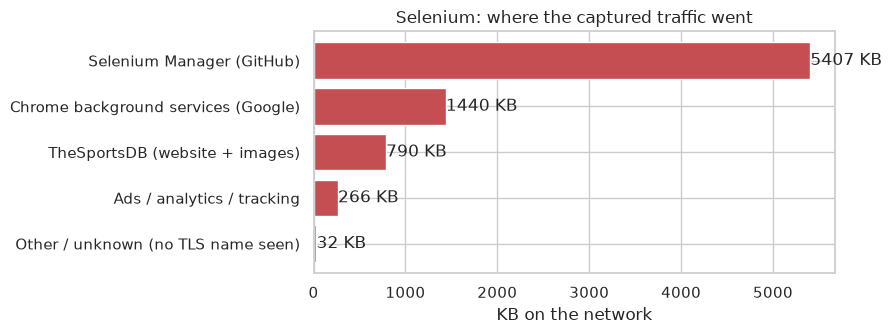

In [10]:
def traffic_group(domain):
    if "thesportsdb.com" in domain:
        return "TheSportsDB (website + images)"
    if "github.io" in domain:
        return "Selenium Manager (GitHub)"
    if any(k in domain for k in ["googletagmanager", "plausible", "cloudflareinsights", "doubleclick",
                                 "www.google.com", "google.com."]):
        return "Ads / analytics / tracking"
    if "google" in domain:
        return "Chrome background services (Google)"
    return "Other / unknown (no TLS name seen)"

if "selenium" in pcap_results:
    db = pcap_results["selenium"]["_domain_bytes"]
    per_domain = pd.DataFrame(db.most_common(), columns=["domain or IP", "bytes"])
    per_domain["KB"] = (per_domain["bytes"] / 1024).round(1)
    per_domain["group"] = per_domain["domain or IP"].map(traffic_group)
    print(per_domain.drop(columns="bytes").head(15).to_string(index=False))

    groups = per_domain.groupby("group")["KB"].sum().sort_values()
    groups.to_csv(NET / "selenium_traffic_groups.csv")
    fig, ax = plt.subplots(figsize=(9, 3.5))
    bars = ax.barh(groups.index, groups.values, color="#C44E52")
    ax.bar_label(bars, fmt="%.0f KB"); ax.set_xlabel("KB on the network")
    ax.set_title("Selenium: where the captured traffic went")
    plt.tight_layout(); plt.savefig(FIG_DIR / "net_selenium_traffic_groups.png", dpi=150); plt.show()

**Important finding:** most of Selenium's traffic is **not the website at all**. A big part is
Selenium Manager and Chrome's own background services, which run every time a fresh browser starts.

**Limitation:** our tcpdump filter only captured **TCP** on ports 80/443. Chrome also uses **QUIC**
(HTTP/3, which runs over **UDP** port 443) for Google servers, as we can see in the `ss` output below.
That traffic is not in the `.pcap`, so Selenium's real traffic was even bigger.

### Packets over time

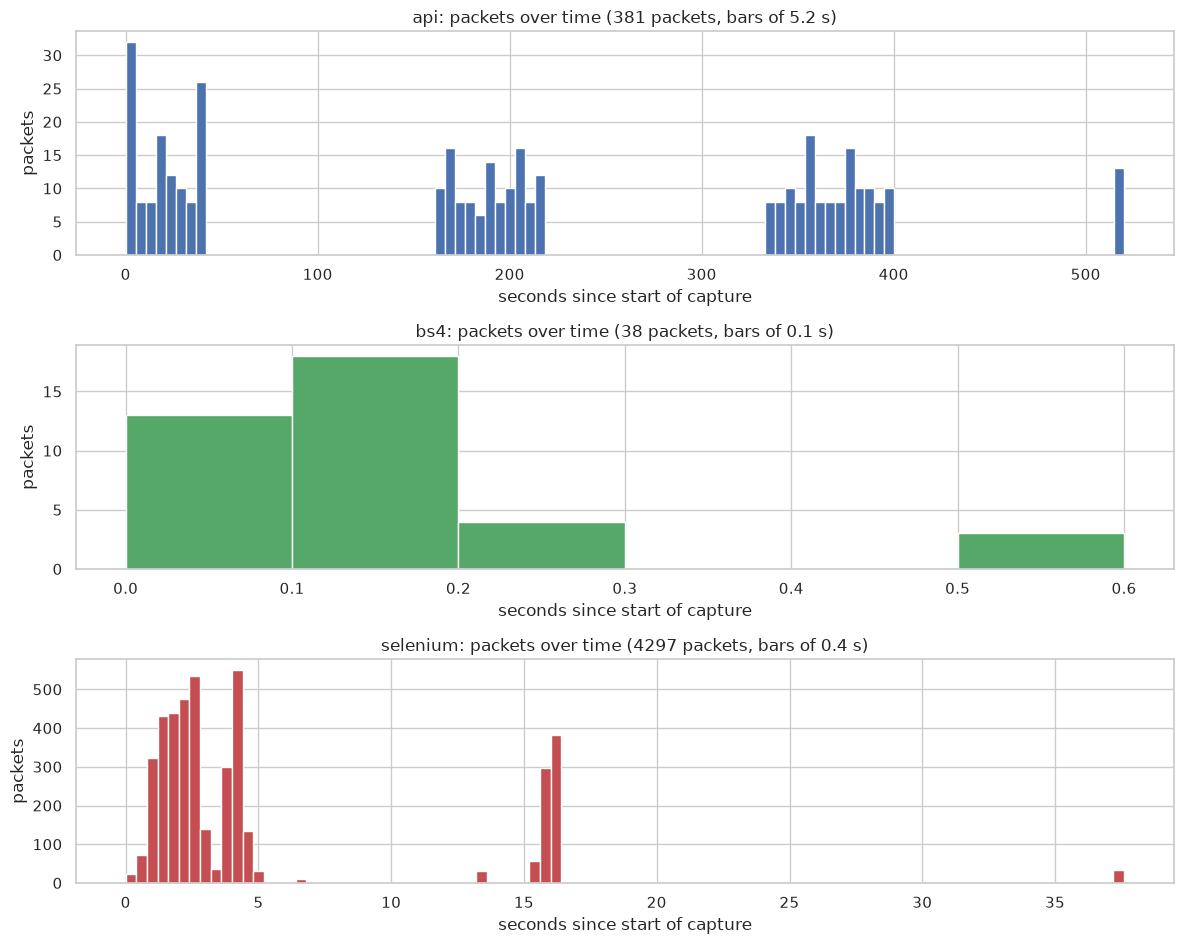

In [11]:
fig, axes = plt.subplots(len(pcap_results), 1, figsize=(12, 3.2 * len(pcap_results)))
axes = np.atleast_1d(axes)
for ax, (m, r) in zip(axes, pcap_results.items()):
    t = r["_times"]
    bin_s = max(0.1, round(t.max() / 100, 1))          # about 100 bars per chart
    ax.hist(t, bins=np.arange(0, t.max() + bin_s, bin_s), color=COLORS[m])
    ax.set_title(f"{m}: packets over time ({r['packets']} packets, bars of {bin_s:g} s)")
    ax.set_xlabel("seconds since start of capture"); ax.set_ylabel("packets")
plt.tight_layout(); plt.savefig(FIG_DIR / "net_packets_over_time.png", dpi=150); plt.show()

- **API:** small regular bursts, one every few seconds (one request per round, then the rate-limit
  pause). The longer gaps are the waits after a "429 Too Many Requests".
- **BeautifulSoup:** one short burst (connection, one page, done).
- **Selenium:** a large burst when the page and all its resources are loaded, then smaller traffic
  while the browser stays open (ads, analytics, background requests) during the ~35 s we read the table.

## 3. Connections seen with `ss`

During each run, `ss -tunp state established` was saved every 0.5 s. We count the **web
connections** (remote port 443 or 80). We ignore `127.0.0.1` (Selenium talking to ChromeDriver on the
same machine) and the system's own DNS (port 53) and time (port 123) traffic.
`udp` lines on port 443 are **QUIC** (HTTP/3) connections opened by Chrome.

In [12]:
def read_ss(path):
    snapshots = path.read_text().split("=== ")[1:]
    max_conn, processes, example = 0, Counter(), ""
    for snap in snapshots:
        lines = [l for l in snap.splitlines()[1:] if l.startswith(("tcp", "udp"))]
        # keep only connections whose remote port is 443 or 80
        external = [l for l in lines if re.search(r"\S+:(443|80)\s", l)]
        if len(external) > max_conn:
            max_conn, example = len(external), "=== " + snap
        for l in external:
            processes.update(re.findall(r'\(\("([^"]+)"', l))
    return len(snapshots), max_conn, processes, example

ss_rows = {}
for m in ["api", "bs4", "selenium"]:
    path = NET / f"{m}_ss.txt"
    if path.exists():
        n, max_conn, procs, example = read_ss(path)
        ss_rows[m] = {"snapshots": n, "max_web_connections": max_conn,
                      "processes": ", ".join(sorted(procs))}
        print(f"----- {m}: busiest snapshot -----")
        print(example[:1500])
pd.DataFrame(ss_rows).T

----- api: busiest snapshot -----
=== 15:29:00.347 ===
Netid Recv-Q Send-Q Local Address:Port  Peer Address:PortProcess                          
tcp   0      0      172.30.29.164:47262 172.67.72.25:443  users:(("python",pid=2022,fd=3))

----- bs4: busiest snapshot -----
=== 15:43:02.352 ===
Netid Recv-Q Send-Q Local Address:Port  Peer Address:PortProcess                          
tcp   0      0      172.30.29.164:34122 172.67.72.25:443  users:(("python",pid=5454,fd=3))

----- selenium: busiest snapshot -----
=== 15:44:54.985 ===
Netid Recv-Q Send-Q Local Address:Port     Peer Address:Port Process                                 
udp   0      0      172.30.29.164:43315  142.251.39.174:443   users:(("chrome",pid=5600,fd=34))      
udp   0      0      172.30.29.164:60311    172.67.72.25:443   users:(("chrome",pid=5600,fd=33))      
udp   0      0      172.30.29.164:46040 142.251.208.134:443   users:(("chrome",pid=5600,fd=37))      
udp   0      0      172.30.29.164:37864  142.251.209.98:

,snapshots,max_web_connections,processes
api,995,1,python
bs4,2,1,python
selenium,74,19,"chrome, selenium-manage"


The API scraper keeps **one** connection (python → TheSportsDB on port 443). BeautifulSoup is so fast
that `ss` almost never sees its connection. Selenium has **many connections at the same time**, all
owned by Chrome.

#### 📷 Screenshot: ss during the API run

> **TODO:** save the screenshot as `network/screenshots/ss_api.png` and replace this box with:
> `![ss during the API run](../network/screenshots/ss_api.png)`

Shows the single established HTTPS connection of the Python API scraper to TheSportsDB.

#### 📷 Screenshot: ss during the Selenium run

> **TODO:** save the screenshot as `network/screenshots/ss_selenium.png` and replace this box with:
> `![ss during the Selenium run](../network/screenshots/ss_selenium.png)`

Shows the many parallel connections opened by Chrome for one page.

## 4. Live monitoring screenshots

#### 📷 Screenshot: nload during the API run

> **TODO:** save the screenshot as `network/screenshots/nload_api.png` and replace this box with:
> `![nload during the API run](../network/screenshots/nload_api.png)`

nload shows the bandwidth used over time: small, regular peaks (one request every few seconds).

#### 📷 Screenshot: nload during the Selenium run

> **TODO:** save the screenshot as `network/screenshots/nload_selenium.png` and replace this box with:
> `![nload during the Selenium run](../network/screenshots/nload_selenium.png)`

A much bigger peak: the browser downloads the page and all its images, scripts and ads.

#### 📷 Screenshot: iftop during the API run

> **TODO:** save the screenshot as `network/screenshots/iftop_api.png` and replace this box with:
> `![iftop during the API run](../network/screenshots/iftop_api.png)`

iftop lists the connections and their speed: only one remote host (TheSportsDB / Cloudflare).

#### 📷 Screenshot: iftop during the Selenium run

> **TODO:** save the screenshot as `network/screenshots/iftop_selenium.png` and replace this box with:
> `![iftop during the Selenium run](../network/screenshots/iftop_selenium.png)`

Many remote hosts at the same time: TheSportsDB, its image server, Google, Cloudflare...

#### 📷 Screenshot: tcpdump output

> **TODO:** save the screenshot as `network/screenshots/tcpdump.png` and replace this box with:
> `![tcpdump output](../network/screenshots/tcpdump.png)`

The first captured packets: the TCP three-way handshake (SYN, SYN-ACK, ACK) and then the encrypted HTTPS traffic.

## 5. Wireshark

#### 📷 Screenshot: Wireshark: Statistics > Conversations (selenium.pcap)

> **TODO:** save the screenshot as `network/screenshots/wireshark_conversations.png` and replace this box with:
> `![Wireshark: Statistics > Conversations (selenium.pcap)](../network/screenshots/wireshark_conversations.png)`

One line per pair of hosts that exchanged packets, with packets and bytes in each direction. For the API there is only one conversation; for Selenium there are many.

#### 📷 Screenshot: Wireshark: Statistics > Protocol Hierarchy (selenium.pcap)

> **TODO:** save the screenshot as `network/screenshots/wireshark_protocols.png` and replace this box with:
> `![Wireshark: Statistics > Protocol Hierarchy (selenium.pcap)](../network/screenshots/wireshark_protocols.png)`

Shows which protocols are inside the capture: Ethernet → IPv4 → TCP → TLS. Almost all data is TLS (encrypted HTTPS), so the content of the pages is not readable.

## 6. Security: firewall test with `ufw`

To show how a firewall controls scraping traffic, we blocked **outgoing HTTPS (port 443)**
with `sudo ufw reject out 443/tcp` and ran the API scraper (2 test rounds), then removed the rule
and ran it again.

In [13]:
for name in ["ufw_status.txt", "ufw_blocked.txt", "ufw_allowed.txt"]:
    path = NET / name
    if path.exists():
        text = path.read_text()
        # Shorten the long repeated error lines so the output stays readable
        text = re.sub(r"HTTPSConnectionPool\(.*?\[Errno", "... [Errno", text)
        print(f"===== {name} =====\n{text}")

===== ufw_status.txt =====
Status: active
Logging: on (low)
Default: deny (incoming), allow (outgoing), disabled (routed)
New profiles: skip

To                         Action      From
--                         ------      ----
443/tcp                    REJECT OUT  Anywhere                  
443/tcp (v6)               REJECT OUT  Anywhere (v6)             


===== ufw_blocked.txt =====
### ufw rule active: reject out 443/tcp
  Request failed (attempt 1): ... [Errno 101] Network is unreachable"))
  Request failed (attempt 2): ... [Errno 101] Network is unreachable"))
  Request failed (attempt 3): ... [Errno 101] Network is unreachable"))
  Request failed (attempt 4): ... [Errno 101] Network is unreachable"))
  Request failed (attempt 5): ... [Errno 101] Network is unreachable"))
Round  1: 0 matches
  Request failed (attempt 1): ... [Errno 101] Network is unreachable"))
  Request failed (attempt 2): ... [Errno 101] Network is unreachable"))
  Request failed (attempt 3): ... [Errno 101

With the rule active, every connection attempt fails immediately with **"Network is unreachable"**
and the scraper collects **0 matches** (but it does not crash, thanks to our error handling: it retries
and then continues). After deleting the rule, the same command collects 20 matches in ~4.5 s.

#### 📷 Screenshot: ufw status and the blocked run

> **TODO:** save the screenshot as `network/screenshots/ufw.png` and replace this box with:
> `![ufw status and the blocked run](../network/screenshots/ufw.png)`

The REJECT OUT rule for 443/tcp and the failed requests of the API scraper.

## 7. Conclusion: which method is best?

| | API | API threaded | BeautifulSoup | Selenium |
|---|---|---|---|---|
| Speed | slow in total (rate limit), fast per request | 20% faster than API | **fastest** | slow |
| Data downloaded | **smallest** | small (+ retries) | medium | **largest** (plus ads/trackers) |
| Requests / servers | 41 requests, 1 server | 50 requests, 1 server | **1 request, 1 server** | 60+ requests, 12+ domains |
| Stability | stable (3 "429" errors) | **12 "429" errors** | stable, but breaks if the HTML layout changes | heavy, most things can go wrong |
| Data quality | structured JSON, official fields | same | needs careful parsing | needs careful parsing |

- **Most efficient for the network:** the **API**. It sends only the data we need (JSON), from one
  server, on one reused connection. Its long total time comes from the **limits of the free key**
  (38 requests + rate limiting), not from the technology. With a paid key the whole season would be
  one request.
- **Fastest in our case:** **BeautifulSoup**, because the website happens to show all 380 matches in
  one page. This is a special case: on many websites the data is split over many pages.
- **Least efficient:** **Selenium**. A full browser downloads many files the scraper never uses
  (images, scripts, ads, analytics) and contacts many extra servers. It is only needed when the data is
  loaded by JavaScript, which is not the case on TheSportsDB.
- **Threads:** with 4 threads the API scraper was about **20% faster** (414 s instead of 517 s), but it
  got **4 times more "429 Too Many Requests" errors** (12 instead of 3) and made 9 extra requests.
  When the server limits the request rate, threads only make us hit the limit faster: they trade
  stability (and politeness towards the server) for a small gain in speed.

**Recommendation:** use the **API** when it gives all the data (most stable, least traffic, clean
data), **BeautifulSoup** when the data is in plain HTML and the API is limited, and **Selenium only when
the page needs JavaScript**.